Mounted at /content/drive


Your model is awake and ready to generate heatmaps!
Loading saved CAMELYON17 external test data...
CAMELYON17 loaded successfully!
Images: (2000, 96, 96, 3)
Labels: (2000,)
Healthy: 1000
Cancer: 1000
Pixel range: 0.0 to 1.0
found da saved brain, loading your previous training progress...


Model successfully loaded and recompiled. Ready to continue training!

Running full Project Patho evaluation...
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step

                   PROJECT PATHO — MODEL EVALUATION                   
Dataset:              CAMELYON17_External_Test_Run_2
Images evaluated:     2,000
Decision threshold:   0.50
----------------------------------------------------------------------
Accuracy:              0.8065
Precision:             0.7299
Sensitivity / Recall:  0.9730
Specificity:           0.6400
F1 Score:              0.8341
ROC-AUC:               0.9557
----------------------------------------------------------------------
CONFUSION MATRIX COUNTS

True Positives:        973
True Negatives:        640
False Positives:       360
False Negatives:       27
----------------------------------------------------------------------
CONFIDENCE / CALIBRATION

Mean confidence:       0.9398
Correct predictions:   0.9565
Wrong predictions:     0.8702
Brier Score:           0.16

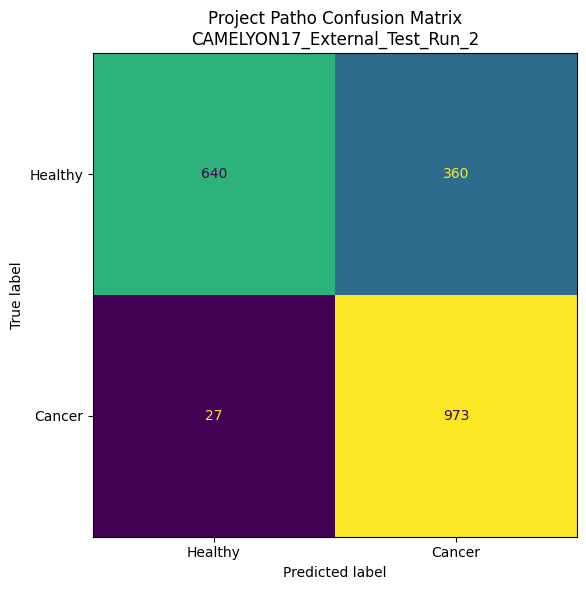

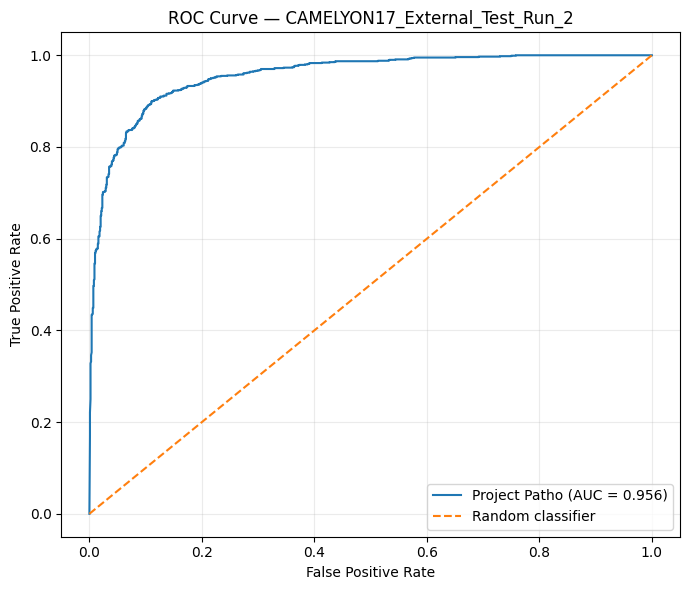

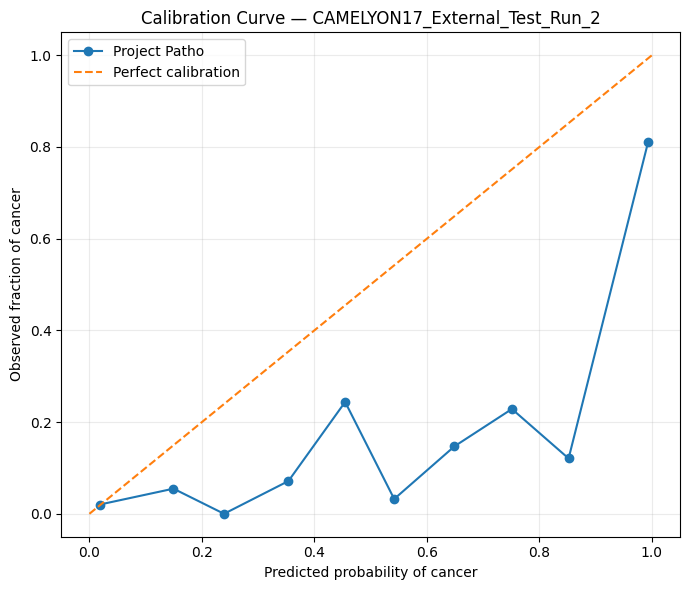


MOST CONFIDENT MODEL ERRORS


,Source_Index,Actual_Condition,AI_Prediction,Cancer_Probability,Prediction_Confidence,Error_Type
534,276217,Healthy,Cancer,1.000000,1.000000,False Positive
1107,275782,Healthy,Cancer,1.000000,1.000000,False Positive
1857,276312,Healthy,Cancer,0.999999,0.999999,False Positive
284,275856,Healthy,Cancer,0.999998,0.999998,False Positive
585,275747,Healthy,Cancer,0.999994,0.999994,False Positive
480,276439,Healthy,Cancer,0.999994,0.999994,False Positive
1051,276197,Healthy,Cancer,0.999992,0.999992,False Positive
916,275948,Healthy,Cancer,0.999984,0.999984,False Positive
326,275744,Healthy,Cancer,0.999981,0.999981,False Positive
369,276168,Healthy,Cancer,0.999963,0.999963,False Positive



Saved evaluation files to:
/content/drive/MyDrive/Pathology_Project/evaluation_results
Generating multiple Grad-CAM visualizations and compiling stats...


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer_9']
Received: inputs=Tensor(shape=(1, 96, 96, 3))
  warnings.warn(msg)



                PATHOLOGY AI PERFORMANCE SUMMARY                 
Slide #    | Actual Condition   | AI Diagnosis    | Confidence | Status  
-----------------------------------------------------------------
1          | Cancer             | Cancer          | 100.0%     | ✅ MATCH 
2          | Cancer             | Cancer          | 100.0%     | ✅ MATCH 
3          | Healthy            | Healthy         | 56.0%      | ✅ MATCH 
4          | Healthy            | Healthy         | 99.4%      | ✅ MATCH 
5          | Cancer             | Cancer          | 100.0%     | ✅ MATCH 

Model saved safely to Google Drive!


In [ ]:
# ========================================================
# STEP 1: MOUNT DRIVE (RUN THIS EVERY TIME YOU OPEN COLAB)
# ========================================================
from google.colab import drive
drive.mount('/content/drive')

# ========================================================
# STEP 2: LOAD REAL SLIDES STRAIGHT FROM H5 FILES
# ========================================================
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras import layers, models
model = load_model("/content/drive/MyDrive/Pathology_Project/my_cancer_model.h5")
print("Your model is awake and ready to generate heatmaps!")
import numpy as np
import matplotlib.pyplot as plt
import cv2
import h5py

# ========================================================
# STEP 2: LOAD CAMELYON17 EXTERNAL TEST DATA FROM DRIVE
# ========================================================

import numpy as np

CAM_DATA_PATH = (
    "/content/drive/MyDrive/Pathology_Project/"
    "camelyon17_balanced_test_2_2000.npz"
)

print("Loading saved CAMELYON17 external test data...")

data = np.load(CAM_DATA_PATH)

# Images were saved as uint8 (0-255).
# Convert them to the exact 0-1 format Project Patho was trained on.
X_val = data["X"].astype("float32") / 255.0

# Cancer labels: 0 = Healthy, 1 = Cancer
y_val = data["y"].astype(int)

# Keep the original CAMELYON17 information
cam_centers = data["center"]
cam_image_ids = data["image_id"]
cam_patients = data["patient"]
cam_slides = data["slide"]

print("CAMELYON17 loaded successfully!")
print("Images:", X_val.shape)
print("Labels:", y_val.shape)

print("Healthy:", np.sum(y_val == 0))
print("Cancer:", np.sum(y_val == 1))

print("Pixel range:", X_val.min(), "to", X_val.max())
# ==========================================
# STEP 3: LOAD EXISTING PROGRESS OR BUILD FRESH (OPTIMIZER RESILIENT)
# ==========================================
import os
import tensorflow as tf
from tensorflow.keras import models, layers

# Define the exact path where your model is saved in Google Drive
MODEL_SAVED_PATH = "/content/drive/MyDrive/Pathology_Project/my_cancer_model.h5"

if os.path.exists(MODEL_SAVED_PATH):
    print("found da saved brain, loading your previous training progress...")
    # Load the exact model weights, layers, and optimizer state from your last run
    model = models.load_model(MODEL_SAVED_PATH)

    # CRITICAL FIX: Recompile the loaded model to reset the active optimizer tracking variables
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    # Extract the base model layer so our Step 5 Grad-CAM function can still find it
    base_model = None
    for layer in model.layers:
        if 'mobilenetv2' in layer.name.lower():
            base_model = layer
            break
    print("Model successfully loaded and recompiled. Ready to continue training!")

else:
    print("🆕 No saved model found. Building a brand-new model framework...")
    # This is your original setup code that runs ONLY the very first time
    base_model = tf.keras.applications.MobileNetV2(input_shape=(96, 96, 3), include_top=False, weights='imagenet')
    base_model.trainable = False

    # Force the internal name to be exactly what our heatmap finder expects
    base_model._name = 'mobilenetv2_1.00_96'

    inputs = tf.keras.Input(shape=(96, 96, 3))
    #data augmentation but i don't know where to put it
    x = layers.RandomFlip("horizontal_and_vertical")(inputs)
    x = layers.RandomRotation(0.2)(x)
    x = base_model(x, training=False)
    # If not using data augmentation, this line handles the input directly:
    #x = base_model(inputs, training=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation='relu')(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = models.Model(inputs, outputs)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    print("New model built and compiled successfully!")

# ==========================================
# STEP 4: TRAIN THE MODEL USING ARRAYS
# ==========================================
# print("Training the AI...")
# We replaced train_dataset and val_dataset with our clean arrays
# model.fit(X_train, y_train, validation_data=(X_val, y_val), batch_size=32, epochs=5)
# print("Training finished!")

# ==========================================
# STEP 5: THE GRAD-CAM HEATMAP FUNCTION (DYNAMIC LAYER FINDER)
# ==========================================
def make_gradcam_heatmap(img_array, model):
    # 1. Automatically find MobileNetV2 inside your main model wrapper
    sub_model = None
    for layer in model.layers:
        if 'mobilenetv2' in layer.name.lower():
            sub_model = layer
            break

    if sub_model is None:
        raise ValueError("Could not automatically locate the MobileNetV2 base layer!")

    # 2. Automatically find the last valid 4D convolutional layer inside MobileNetV2
    last_conv_layer_name = None
    for layer in reversed(sub_model.layers):
        try:
            if len(layer.output.shape) == 4:
                last_conv_layer_name = layer.name
                break
        except:
            continue

    # 3. Build the feature map tracking sub-graph
    grad_model = models.Model(
        inputs=[sub_model.input],
        outputs=[sub_model.get_layer(last_conv_layer_name).output, sub_model.output]
    )

    # 4. Calculate gradients through the entire custom tail end of your network
    with tf.GradientTape() as tape:
        conv_outputs, sub_outputs = grad_model(img_array)

        # Manually flow the sub_outputs through the remaining dense layers to reach the final guess
        # We find them dynamically by checking their layer names
        x = sub_outputs
        found_gap = False
        for layer in model.layers:
            # Once we cross the base model, pass features through the remaining head layers
            if found_gap or 'global_average_pooling' in layer.name.lower():
                found_gap = True
                x = layer(x)
        preds = x
        class_channel = preds[:, 0]

    # Calculate backprop gradients showing what the model focused on
    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalize heatmap intensity safely
    heatmap = tf.maximum(heatmap, 0)
    max_val = tf.reduce_max(heatmap)
    if max_val == 0:
        max_val = 1e-10
    heatmap = heatmap / max_val
    return heatmap.numpy()
# ========================================================
# STEP 5.5: FULL RESEARCH-STYLE MODEL EVALUATION
# ========================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    brier_score_loss,
    ConfusionMatrixDisplay
)

from sklearn.calibration import calibration_curve


# Folder where Project Patho evaluation results will be saved
RESULTS_DIR = "/content/drive/MyDrive/Pathology_Project/evaluation_results"
os.makedirs(RESULTS_DIR, exist_ok=True)


# --------------------------------------------------------
# EXPECTED CALIBRATION ERROR
# --------------------------------------------------------
# Measures whether the model's stated confidence actually
# matches how often it is correct.
#
# Lower = better
# Perfect calibration = 0
# --------------------------------------------------------

def calculate_ece(y_true, y_prob, n_bins=10):

    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob)

    # Convert cancer probability into predicted class
    y_pred = (y_prob >= 0.5).astype(int)

    # TRUE confidence of the prediction:
    #
    # Cancer prediction at 0.90 -> confidence = 0.90
    # Healthy prediction at 0.10 -> confidence = 0.90
    confidence = np.where(
        y_pred == 1,
        y_prob,
        1 - y_prob
    )

    correct = (y_pred == y_true).astype(int)

    bin_edges = np.linspace(0, 1, n_bins + 1)

    ece = 0.0

    for i in range(n_bins):

        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == n_bins - 1:
            in_bin = (confidence >= lower) & (confidence <= upper)
        else:
            in_bin = (confidence >= lower) & (confidence < upper)

        bin_count = np.sum(in_bin)

        if bin_count > 0:

            bin_accuracy = np.mean(correct[in_bin])
            bin_confidence = np.mean(confidence[in_bin])

            bin_weight = bin_count / len(y_true)

            ece += bin_weight * abs(
                bin_accuracy - bin_confidence
            )

    return ece


# ========================================================
# MAIN EVALUATION FUNCTION
# ========================================================

def evaluate_patho_model(
    model,
    X,
    y_true,
    dataset_name="CAMELYON17_External_Test_Run_2",
    threshold=0.5,
    source_indices=None
):

    print("\nRunning full Project Patho evaluation...")

    y_true = np.asarray(y_true).astype(int).ravel()

    # ----------------------------------------------------
    # RUN MODEL ON ALL IMAGES
    # ----------------------------------------------------

    y_prob = model.predict(
        X,
        batch_size=32,
        verbose=1
    ).ravel()

    # Probability >= 0.5 means Cancer
    y_pred = (y_prob >= threshold).astype(int)


    # ----------------------------------------------------
    # TRUE PREDICTION CONFIDENCE
    # ----------------------------------------------------

    confidence = np.where(
        y_pred == 1,
        y_prob,
        1 - y_prob
    )

    correct = (y_pred == y_true)


    # ----------------------------------------------------
    # CONFUSION MATRIX
    #
    # Labels:
    # 0 = Healthy
    # 1 = Cancer
    # ----------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()


    # ----------------------------------------------------
    # STANDARD METRICS
    # ----------------------------------------------------

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    sensitivity = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )


    # Specificity = ability to correctly identify healthy tissue
    if (tn + fp) > 0:
        specificity = tn / (tn + fp)
    else:
        specificity = np.nan


    # ----------------------------------------------------
    # ROC-AUC
    # ----------------------------------------------------

    # ROC-AUC requires both cancer AND healthy examples
    if len(np.unique(y_true)) == 2:

        roc_auc = roc_auc_score(
            y_true,
            y_prob
        )

    else:

        roc_auc = np.nan
        print(
            "Warning: ROC-AUC could not be calculated "
            "because this dataset contains only one class."
        )


    # ----------------------------------------------------
    # CALIBRATION METRICS
    # ----------------------------------------------------

    brier = brier_score_loss(
        y_true,
        y_prob
    )

    ece = calculate_ece(
        y_true,
        y_prob,
        n_bins=10
    )


    # ----------------------------------------------------
    # CONFIDENCE ANALYSIS
    # ----------------------------------------------------

    mean_confidence = np.mean(confidence)

    if np.any(correct):

        correct_confidence = np.mean(
            confidence[correct]
        )

    else:

        correct_confidence = np.nan


    if np.any(~correct):

        wrong_confidence = np.mean(
            confidence[~correct]
        )

    else:

        wrong_confidence = np.nan


    # ----------------------------------------------------
    # PRINT PERFORMANCE REPORT
    # ----------------------------------------------------

    print("\n" + "=" * 70)
    print(f"{'PROJECT PATHO — MODEL EVALUATION':^70}")
    print("=" * 70)

    print(f"Dataset:              {dataset_name}")
    print(f"Images evaluated:     {len(y_true):,}")
    print(f"Decision threshold:   {threshold:.2f}")

    print("-" * 70)

    print(f"Accuracy:              {accuracy:.4f}")
    print(f"Precision:             {precision:.4f}")
    print(f"Sensitivity / Recall:  {sensitivity:.4f}")
    print(f"Specificity:           {specificity:.4f}")
    print(f"F1 Score:              {f1:.4f}")

    if np.isnan(roc_auc):
        print("ROC-AUC:               N/A")
    else:
        print(f"ROC-AUC:               {roc_auc:.4f}")

    print("-" * 70)

    print("CONFUSION MATRIX COUNTS")
    print()

    print(f"True Positives:        {tp:,}")
    print(f"True Negatives:        {tn:,}")
    print(f"False Positives:       {fp:,}")
    print(f"False Negatives:       {fn:,}")

    print("-" * 70)

    print("CONFIDENCE / CALIBRATION")
    print()

    print(f"Mean confidence:       {mean_confidence:.4f}")
    print(f"Correct predictions:   {correct_confidence:.4f}")

    if np.isnan(wrong_confidence):
        print("Wrong predictions:     N/A")
    else:
        print(f"Wrong predictions:     {wrong_confidence:.4f}")

    print(f"Brier Score:           {brier:.4f}")
    print(f"ECE:                   {ece:.4f}")

    print("=" * 70)


    # ====================================================
    # CREATE PER-IMAGE RESULTS TABLE
    # ====================================================

    if source_indices is None:
        source_indices = np.arange(len(y_true))


    results_df = pd.DataFrame({

        "Source_Index": source_indices,

        "Actual_Label": y_true,

        "Actual_Condition": np.where(
            y_true == 1,
            "Cancer",
            "Healthy"
        ),

        "Cancer_Probability": y_prob,

        "Predicted_Label": y_pred,

        "AI_Prediction": np.where(
            y_pred == 1,
            "Cancer",
            "Healthy"
        ),

        "Prediction_Confidence": confidence,

        "Correct": correct

    })


    # ----------------------------------------------------
    # LABEL ERROR TYPES
    # ----------------------------------------------------

    results_df["Error_Type"] = "Correct"

    results_df.loc[
        (results_df["Actual_Label"] == 0) &
        (results_df["Predicted_Label"] == 1),
        "Error_Type"
    ] = "False Positive"

    results_df.loc[
        (results_df["Actual_Label"] == 1) &
        (results_df["Predicted_Label"] == 0),
        "Error_Type"
    ] = "False Negative"


    # ----------------------------------------------------
    # SAVE ALL PREDICTIONS
    # ----------------------------------------------------

    safe_name = dataset_name.replace(" ", "_")

    predictions_path = (
        f"{RESULTS_DIR}/{safe_name}_predictions.csv"
    )

    results_df.to_csv(
        predictions_path,
        index=False
    )


    # Save false positives separately
    false_positives = results_df[
        results_df["Error_Type"] == "False Positive"
    ].sort_values(
        "Prediction_Confidence",
        ascending=False
    )

    false_positives.to_csv(
        f"{RESULTS_DIR}/{safe_name}_false_positives.csv",
        index=False
    )


    # Save false negatives separately
    false_negatives = results_df[
        results_df["Error_Type"] == "False Negative"
    ].sort_values(
        "Prediction_Confidence",
        ascending=False
    )

    false_negatives.to_csv(
        f"{RESULTS_DIR}/{safe_name}_false_negatives.csv",
        index=False
    )


    # ====================================================
    # SAVE METRICS SUMMARY
    # ====================================================

    metrics_dictionary = {

        "Dataset": dataset_name,

        "Images": len(y_true),

        "Accuracy": accuracy,

        "Precision": precision,

        "Sensitivity_Recall": sensitivity,

        "Specificity": specificity,

        "F1": f1,

        "ROC_AUC": roc_auc,

        "True_Positive": tp,

        "True_Negative": tn,

        "False_Positive": fp,

        "False_Negative": fn,

        "Mean_Confidence": mean_confidence,

        "Correct_Mean_Confidence": correct_confidence,

        "Incorrect_Mean_Confidence": wrong_confidence,

        "Brier_Score": brier,

        "ECE": ece

    }


    metrics_df = pd.DataFrame(
        [metrics_dictionary]
    )

    metrics_df.to_csv(
        f"{RESULTS_DIR}/{safe_name}_metrics.csv",
        index=False
    )


    # ====================================================
    # CONFUSION MATRIX GRAPH
    # ====================================================

    fig, ax = plt.subplots(
        figsize=(6, 6)
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "Healthy",
            "Cancer"
        ]
    )

    display_cm.plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )

    plt.title(
        f"Project Patho Confusion Matrix\n{dataset_name}"
    )

    plt.tight_layout()

    plt.savefig(
        f"{RESULTS_DIR}/{safe_name}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


    # ====================================================
    # ROC CURVE
    # ====================================================

    if len(np.unique(y_true)) == 2:

        fpr, tpr, thresholds = roc_curve(
            y_true,
            y_prob
        )

        plt.figure(
            figsize=(7, 6)
        )

        plt.plot(
            fpr,
            tpr,
            label=f"Project Patho (AUC = {roc_auc:.3f})"
        )

        plt.plot(
            [0, 1],
            [0, 1],
            linestyle="--",
            label="Random classifier"
        )

        plt.xlabel(
            "False Positive Rate"
        )

        plt.ylabel(
            "True Positive Rate"
        )

        plt.title(
            f"ROC Curve — {dataset_name}"
        )

        plt.legend()

        plt.grid(
            alpha=0.25
        )

        plt.tight_layout()

        plt.savefig(
            f"{RESULTS_DIR}/{safe_name}_roc_curve.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()


    # ====================================================
    # CALIBRATION / RELIABILITY CURVE
    # ====================================================

    if len(np.unique(y_true)) == 2:

        fraction_positive, mean_predicted_value = calibration_curve(
            y_true,
            y_prob,
            n_bins=10,
            strategy="uniform"
        )

        plt.figure(
            figsize=(7, 6)
        )

        plt.plot(
            mean_predicted_value,
            fraction_positive,
            marker="o",
            label="Project Patho"
        )

        plt.plot(
            [0, 1],
            [0, 1],
            linestyle="--",
            label="Perfect calibration"
        )

        plt.xlabel(
            "Predicted probability of cancer"
        )

        plt.ylabel(
            "Observed fraction of cancer"
        )

        plt.title(
            f"Calibration Curve — {dataset_name}"
        )

        plt.legend()

        plt.grid(
            alpha=0.25
        )

        plt.tight_layout()

        plt.savefig(
            f"{RESULTS_DIR}/{safe_name}_calibration_curve.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()


    # ====================================================
    # SHOW MOST CONFIDENT ERRORS
    # ====================================================

    errors = results_df[
        results_df["Correct"] == False
    ].sort_values(
        "Prediction_Confidence",
        ascending=False
    )


    print("\nMOST CONFIDENT MODEL ERRORS")

    if len(errors) == 0:

        print("No errors in this evaluation set.")

    else:

        display(
            errors[
                [
                    "Source_Index",
                    "Actual_Condition",
                    "AI_Prediction",
                    "Cancer_Probability",
                    "Prediction_Confidence",
                    "Error_Type"
                ]
            ].head(10)
        )


    print("\nSaved evaluation files to:")
    print(RESULTS_DIR)


    return metrics_dictionary, results_df, y_prob

# ========================================================
# RUN FULL EVALUATION ON YOUR CURRENT VALIDATION SET
# ========================================================

# These are the ORIGINAL PCam indices corresponding to X_val.
# This makes it much easier to find bad predictions later.

#VAL_START_INDEX = STARTINDEX + split_index

cam_metrics, cam_predictions, cam_probabilities = evaluate_patho_model(

    model=model,

    X=X_val,

    y_true=y_val,

    dataset_name="CAMELYON17_External_Test_Run_2",

    threshold=0.5,

    source_indices=cam_image_ids

)


# ==========================================
# STEP 6: TEST MULTIPLE SLIDES & GENERATE SUMMARY TABLE
# ==========================================
if len(X_val) == 0:
    print("⚠️ Warning: X_val is currently empty! Please re-run Step 2 with a valid data slice.")
import ipywidgets as widgets
from IPython.display import display
import io
print("Generating multiple Grad-CAM visualizations and compiling stats...")

table_results = []
NUM_TEST_IMAGES = 5

for i in range(NUM_TEST_IMAGES):
    test_img = X_val[i]
    test_label = y_val[i]

    img_for_prediction = np.expand_dims(test_img, axis=0)
    prediction = cam_probabilities[i]

    actual_string = "Cancer" if test_label == 1 else "Healthy"
    ai_string = "Cancer" if prediction >= 0.5 else "Healthy"
    is_correct = "✅ MATCH" if actual_string == ai_string else "❌ ERROR"

    prediction_confidence = prediction if prediction >= 0.5 else 1 - prediction

    table_results.append({
        "Slide #": i + 1,
        "Actual": actual_string,
        "AI Prediction": ai_string,
        "Cancer Probability": f"{prediction*100:.1f}%",
        "Confidence": f"{prediction_confidence*100:.1f}%",
        "Result": is_correct
    })

    # Generate visual heatmap using our dynamic name-independent function
    heatmap = make_gradcam_heatmap(img_for_prediction, model)
    heatmap_resized = cv2.resize(heatmap, (96, 96))
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)

    heatmap_colored_normalized = heatmap_colored / 255.0
    superimposed_img = heatmap_colored_normalized * 0.4 + test_img
    superimposed_img = np.clip(superimposed_img, 0, 1)

    fig, axes = plt.subplots(1, 3, figsize=(10, 4))

    axes[0].set_title(f"Slide #{i+1} (Actual: {actual_string})", fontsize=10)
    axes[0].imshow(test_img)
    axes[0].axis('off')

    axes[1].set_title("AI Attention Map", fontsize=10)
    axes[1].imshow(heatmap_resized, cmap='jet')
    axes[1].axis('off')

    axes[2].set_title(f"Overlay - AI Guess: {prediction*100:.1f}% Cancer", fontsize=10)
    axes[2].imshow(superimposed_img)
    axes[2].axis('off')

    plt.tight_layout()

    buf = io.BytesIO()
    plt.savefig(buf, format='png')
    buf.seek(0)
    plt.close()

    image_widget = widgets.Image(value=buf.read(), format='png', width=700)
    comment_box = widgets.Textarea(
        placeholder='Type notes here...',
        layout=widgets.Layout(width='250px', height='120px')
        )

    display(widgets.HBox([image_widget, comment_box]))

    # Plot visual frames






# PRINT PERFORMANCE BOARD
print("\n" + "="*65)
print(f"{'PATHOLOGY AI PERFORMANCE SUMMARY':^65}")
print("="*65)
print(f"{'Slide #':<10} | {'Actual Condition':<18} | {'AI Diagnosis':<15} | {'Confidence':<10} | {'Status':<8}")
print("-"*65)

for row in table_results:
    print(f"{row['Slide #']:<10} | {row['Actual']:<18} | {row['AI Prediction']:<15} | {row['Confidence']:<10} | {row['Result']:<8}")

print("="*65)

# Save final model state
model.save("/content/drive/MyDrive/Pathology_Project/my_cancer_model.h5")
print("\nModel saved safely to Google Drive!")

In [ ]:
import numpy as np

paths = {
    "Run 2": "/content/drive/MyDrive/Pathology_Project/camelyon17_balanced_test_2000.npz",
    "Run 3": "/content/drive/MyDrive/Pathology_Project/camelyon17_balanced_test_2_2000.npz"
}

for name, path in paths.items():

    data = np.load(path)

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print("Images:", len(data["y"]))
    print("Healthy:", np.sum(data["y"] == 0))
    print("Cancer:", np.sum(data["y"] == 1))

    print("Unique patients:", len(np.unique(data["patient"])))
    print("Unique slides:", len(np.unique(data["slide"])))
    print("Centers:", np.unique(data["center"]))

    print("Patients:", np.unique(data["patient"]))
    print("Slides:", np.unique(data["slide"]))


Run 2
Images: 2000
Healthy: 1000
Cancer: 1000
Unique patients: 9
Unique slides: 10
Centers: [2]
Patients: [40 41 42 44 45 46 48 51 52]
Slides: [20 21 22 23 24 25 26 27 28 29]

Run 3
Images: 2000
Healthy: 1000
Cancer: 1000
Unique patients: 9
Unique slides: 10
Centers: [2]
Patients: [40 41 42 44 45 46 48 51 52]
Slides: [20 21 22 23 24 25 26 27 28 29]


In [ ]:
import numpy as np
import pandas as pd

paths = {
    "Run 2": "/content/drive/MyDrive/Pathology_Project/camelyon17_balanced_test_2000.npz",
    "Run 3": "/content/drive/MyDrive/Pathology_Project/camelyon17_balanced_test_2_2000.npz"
}

for run_name, path in paths.items():

    data = np.load(path)

    df = pd.DataFrame({
        "slide": data["slide"],
        "patient": data["patient"],
        "label": data["y"]
    })

    summary = (
        df.groupby(["slide", "patient", "label"])
        .size()
        .unstack(fill_value=0)
        .reset_index()
    )

    summary = summary.rename(columns={
        0: "Healthy",
        1: "Cancer"
    })

    if "Healthy" not in summary.columns:
        summary["Healthy"] = 0

    if "Cancer" not in summary.columns:
        summary["Cancer"] = 0

    summary["Total"] = (
        summary["Healthy"] +
        summary["Cancer"]
    )

    summary["Cancer_Percent"] = (
        summary["Cancer"] /
        summary["Total"] *
        100
    ).round(1)

    print("\n" + "=" * 70)
    print(run_name)
    print("=" * 70)

    display(
        summary[
            [
                "slide",
                "patient",
                "Healthy",
                "Cancer",
                "Total",
                "Cancer_Percent"
            ]
        ]
    )


Run 2


label,slide,patient,Healthy,Cancer,Total,Cancer_Percent
0,20,40,64,27,91,29.7
1,21,41,52,10,62,16.1
2,22,42,524,963,1487,64.8
3,23,44,31,0,31,0.0
4,24,45,94,0,94,0.0
5,25,46,36,0,36,0.0
6,26,46,41,0,41,0.0
7,27,48,36,0,36,0.0
8,28,51,56,0,56,0.0
9,29,52,66,0,66,0.0



Run 3


label,slide,patient,Healthy,Cancer,Total,Cancer_Percent
0,20,40,82,0,82,0.0
1,21,41,89,0,89,0.0
2,22,42,64,1000,1064,94.0
3,23,44,68,0,68,0.0
4,24,45,156,0,156,0.0
5,25,46,74,0,74,0.0
6,26,46,63,0,63,0.0
7,27,48,101,0,101,0.0
8,28,51,132,0,132,0.0
9,29,52,171,0,171,0.0
